In [1]:
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.impute import SimpleImputer
import itertools
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    f1_score, accuracy_score, classification_report, 
    confusion_matrix, roc_auc_score, balanced_accuracy_score, matthews_corrcoef
)
from imblearn.over_sampling import SMOTE
import warnings
import optuna
from lightgbm import LGBMClassifier
import os
import warnings

In [2]:
with open('/kaggle/input/notebooks/matildeteixeira/wesad-preprocess/processed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X            = data['X']
y            = data['y']
groups       = data['groups']
feature_cols = data['feature_cols']
logo     = LeaveOneGroupOut()
results = []

In [3]:
print([col for col in feature_cols if 'acc' in col.lower()])
print([col for col in feature_cols if 'hr' in col.lower()])
print([col for col in feature_cols if 'ibi' in col.lower() or 'rmssd' in col.lower() or 'sdnn' in col.lower()])

['acc_wrist_mean', 'acc_wrist_std', 'acc_wrist_min', 'acc_wrist_max', 'acc_wrist_p25', 'acc_wrist_p75', 'acc_wrist_skew', 'acc_wrist_kurtosis', 'acc_chest_mean', 'acc_chest_std', 'acc_chest_min', 'acc_chest_max', 'acc_chest_p25', 'acc_chest_p75', 'acc_chest_skew', 'acc_chest_kurtosis']
['hr_mean', 'hr_std', 'hr_min', 'hr_max', 'hr_p25', 'hr_p75', 'hr_skew', 'hr_kurtosis', 'ecg_hr_mean', 'ecg_hr_std', 'ecg_hr_min', 'ecg_hr_max', 'ecg_hr_p25', 'ecg_hr_p75', 'ecg_hr_skew', 'ecg_hr_kurtosis']
['ibi_mean', 'ibi_std', 'ibi_min', 'ibi_max', 'ibi_p25', 'ibi_p75', 'ibi_skew', 'ibi_kurtosis', 'rmssd_mean', 'rmssd_std', 'rmssd_min', 'rmssd_max', 'rmssd_p25', 'rmssd_p75', 'rmssd_skew', 'rmssd_kurtosis', 'sdnn_mean', 'sdnn_std', 'sdnn_min', 'sdnn_max', 'sdnn_p25', 'sdnn_p75', 'sdnn_skew', 'sdnn_kurtosis', 'ecg_ibi_mean', 'ecg_ibi_std', 'ecg_ibi_min', 'ecg_ibi_max', 'ecg_ibi_p25', 'ecg_ibi_p75', 'ecg_ibi_skew', 'ecg_ibi_kurtosis', 'ecg_rmssd_mean', 'ecg_rmssd_std', 'ecg_rmssd_min', 'ecg_rmssd_max', 

In [4]:
demographic_cols = ['age', 'gender', 'coffee_last_hour', 'sports', 'smoker', 'ill']

selected_features = [col for col in feature_cols if any(
    col.startswith(sig) for sig in ['acc_wrist', 'hr_', 'ibi_', 'rmssd_', 'sdnn_']
)] + [c for c in demographic_cols if c in feature_cols]

print(f"{len(selected_features)} features no total")

46 features no total


In [5]:
X = X[selected_features]

**XGBoost**

In [6]:
param_grid = {
    'n_estimators':  [75, 100, 200],
    'max_depth':     [5, 6, 7],
    'learning_rate': [0.05, 0.1, 0.2],
}
keys   = list(param_grid.keys())
values = list(param_grid.values())
logo   = LeaveOneGroupOut()

In [7]:
def evaluate_xgb(X, y, groups, best_params, use_smote=True):
    logo = LeaveOneGroupOut()
    all_y_true, all_y_pred, all_y_probs = [], [], []
    fold_f1s, fold_mccs, all_cms = [], [], []

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_train = imputer.fit_transform(scaler.fit_transform(X_train))
        X_test  = imputer.transform(scaler.transform(X_test))

        if use_smote:
            X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

        model = XGBClassifier(**best_params, eval_metric='logloss', random_state=42)
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)
        all_y_probs.extend(y_prob)
        fold_f1s.append(f1_score(y_test, y_pred, zero_division=0))
        fold_mccs.append(matthews_corrcoef(y_test, y_pred))
        all_cms.append(confusion_matrix(y_test, y_pred))

    return {
        'y_test':   np.array(all_y_true),
        'y_pred':   np.array(all_y_pred),
        'y_prob':   np.array(all_y_probs),
        'f1':       np.mean(fold_f1s),
        'f1_std':   np.std(fold_f1s),
        'accuracy': accuracy_score(all_y_true, all_y_pred),
        'bal_acc':  balanced_accuracy_score(all_y_true, all_y_pred),
        'mcc':      np.mean(fold_mccs),
        'roc_auc':  roc_auc_score(all_y_true, all_y_probs),
        'cm':       np.sum(all_cms, axis=0),
        'model':    model,  # último fold, para feature importance
    }

In [8]:
def run_xgb(use_smote):
    label = "COM SMOTE" if use_smote else "SEM SMOTE"
    print(f"\n{'='*50}\nA correr XGBoost {label}...\n{'='*50}")

    # Grid Search
    best_f1, best_params = -1, None
    for combo in itertools.product(*values):
        params   = dict(zip(keys, combo))
        fold_f1s = []

        for train_idx, test_idx in logo.split(X, y, groups):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            scaler  = StandardScaler()
            imputer = SimpleImputer(strategy='mean')
            X_train = imputer.fit_transform(scaler.fit_transform(X_train))
            X_test  = imputer.transform(scaler.transform(X_test))

            if use_smote:
                X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

            model = XGBClassifier(**params, eval_metric='logloss', random_state=42)
            model.fit(X_train, y_train)
            fold_f1s.append(f1_score(y_test, model.predict(X_test), zero_division=0))

        mean_f1 = np.mean(fold_f1s)
        if mean_f1 > best_f1:
            best_f1, best_params = mean_f1, params
            print(f"Novo melhor F1: {best_f1:.3f} -> {best_params}")

    print(f"Melhores parâmetros {label}: {best_params}")

    # Avaliação Final
    res = evaluate_xgb(X, y, groups, best_params, use_smote=use_smote)

    # Métricas
    print(classification_report(res['y_test'], res['y_pred']))
    print(f"ROC-AUC:            {res['roc_auc']:.3f}")
    print(f"Balanced Accuracy:  {res['bal_acc']:.3f}")
    print(f"MCC:                {res['mcc']:.3f}")
    print(f"F1 Std (por fold):  {res['f1_std']:.3f}")

    # Confusion Matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        res['cm'], annot=True, fmt='d', cmap='Blues',
        xticklabels=['Non-Stress', 'Stress'],
        yticklabels=['Non-Stress', 'Stress'],
        linewidths=0.5, ax=ax
    )
    ax.set_title(f'Confusion Matrix – XGBoost {label}', fontsize=13)
    ax.set_xlabel('Predicted Label'); ax.set_ylabel('True Label')
    plt.tight_layout(); plt.show()

    # Feature Importance — todas
    importances = res['model'].feature_importances_
    indices     = np.argsort(importances)
    plt.figure(figsize=(20, 19))
    plt.barh(np.array(selected_features)[indices], importances[indices])
    plt.title(f"Feature Importance — XGBoost {label}")
    plt.tight_layout(); plt.show()

    # Feature Importance — Questionário
    quest_cols = [c for c in ['age', 'gender', 'coffee_last_hour', 'sports', 'smoker', 'ill'] 
              if c in list(selected_features)]
    if quest_cols:
        quest_indices = [list(selected_features).index(c) for c in quest_cols]
        quest_importances = res['model'].feature_importances_[quest_indices]
        indices = np.argsort(quest_importances)
        plt.figure(figsize=(8, 5))
        plt.barh(np.array(quest_cols)[indices], quest_importances[indices])
        plt.title('Feature Importance — Questionário')
        plt.tight_layout()
        plt.show()

    # Guardar pkl
    smote_tag = 'smote' if use_smote else 'no_smote'
    roc_data  = {k: v for k, v in res.items() if k != 'model'}
    roc_data.update({'smote': use_smote, 'best_params': best_params, 'model': 'XGBoost'})
    os.makedirs('/kaggle/working/roc_data', exist_ok=True)
    fname = f'/kaggle/working/roc_data/xgb_{smote_tag}.pkl'
    with open(fname, 'wb') as f:
        pickle.dump(roc_data, f)
    print(f"Guardado em: {fname}")


A correr XGBoost COM SMOTE...
Novo melhor F1: 0.680 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.05}
Melhores parâmetros COM SMOTE: {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.05}
              precision    recall  f1-score   support

           0       0.83      0.86      0.84     17577
           1       0.74      0.68      0.71      9966

    accuracy                           0.80     27543
   macro avg       0.78      0.77      0.78     27543
weighted avg       0.79      0.80      0.80     27543

ROC-AUC:            0.820
Balanced Accuracy:  0.772
MCC:                0.569
F1 Std (por fold):  0.243


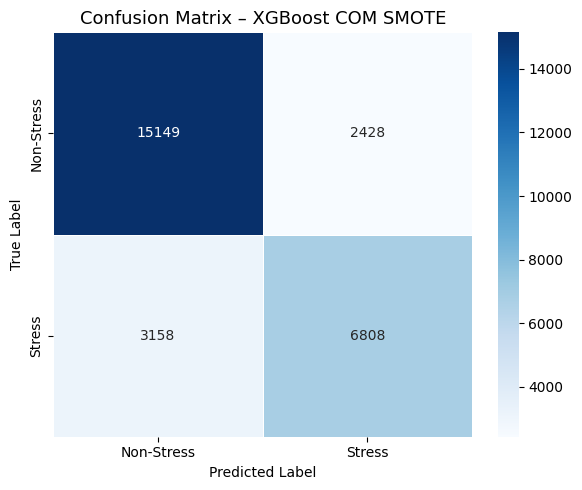

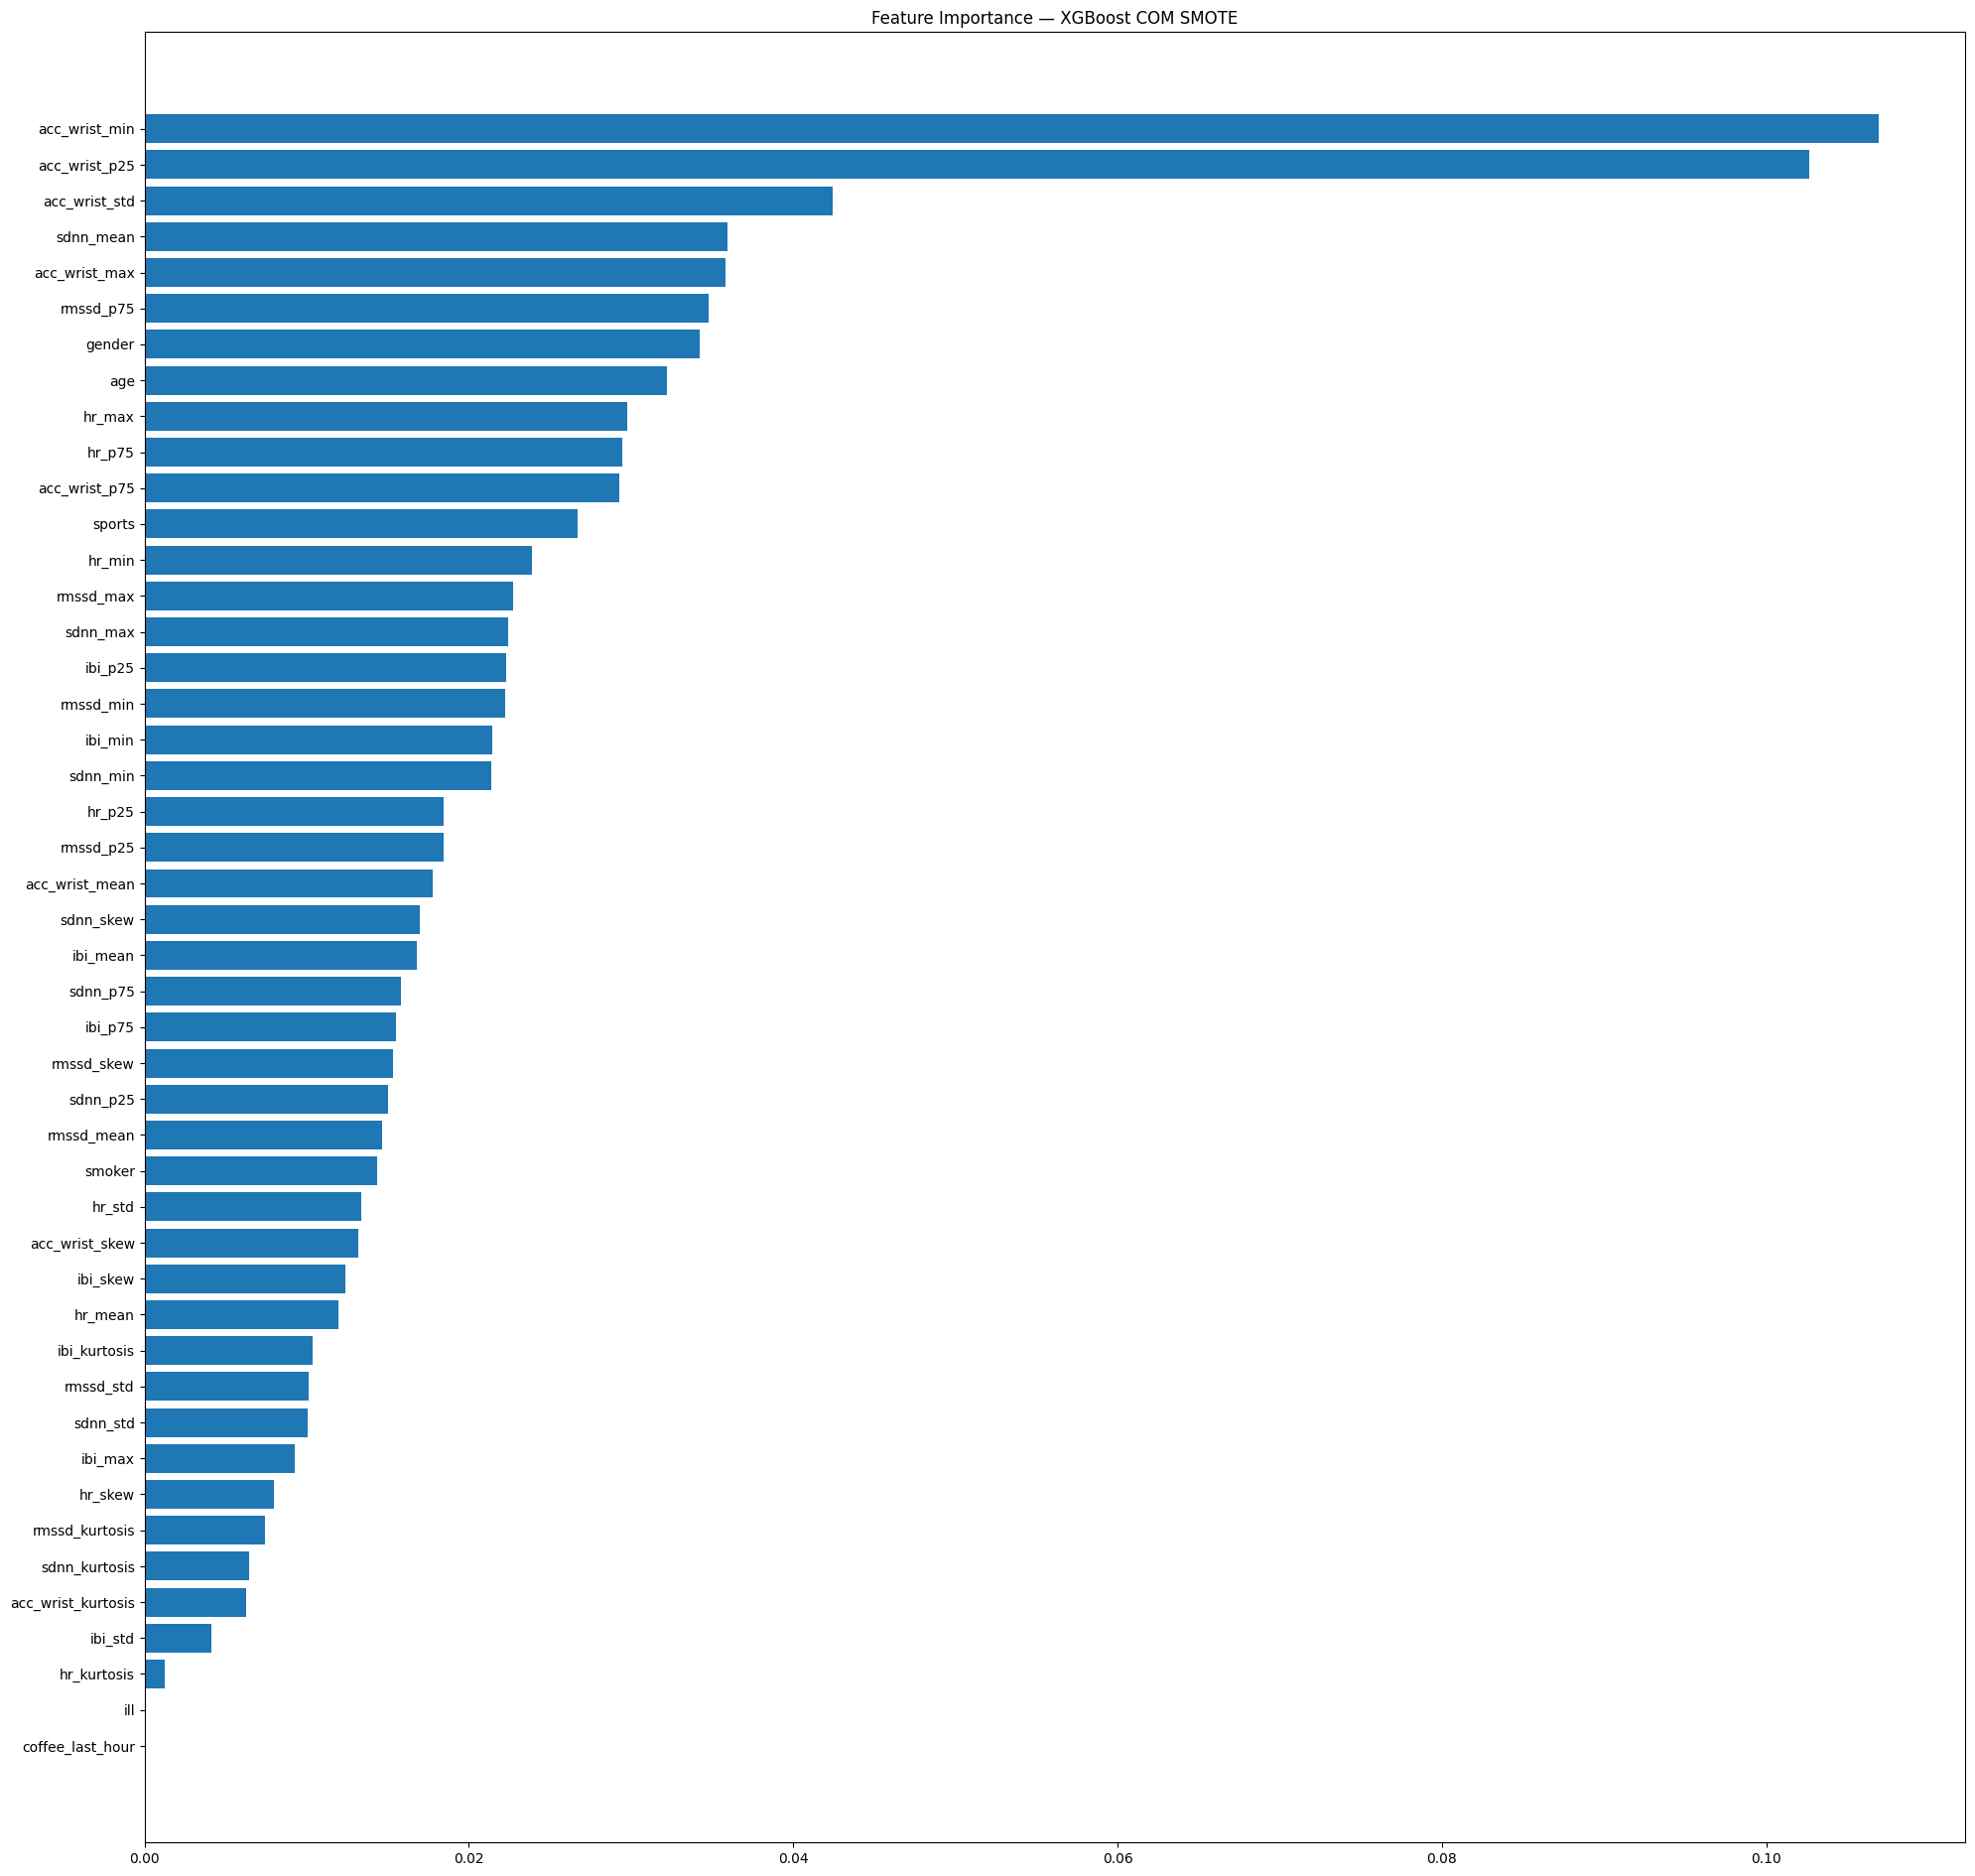

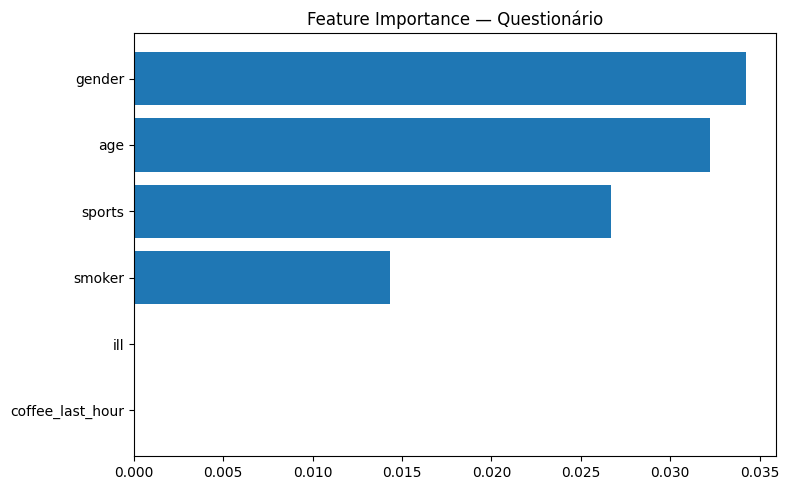

Guardado em: /kaggle/working/roc_data/xgb_smote.pkl

A correr XGBoost SEM SMOTE...
Novo melhor F1: 0.677 -> {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.05}
Melhores parâmetros SEM SMOTE: {'n_estimators': 75, 'max_depth': 5, 'learning_rate': 0.05}
              precision    recall  f1-score   support

           0       0.82      0.89      0.85     17577
           1       0.77      0.66      0.71      9966

    accuracy                           0.81     27543
   macro avg       0.80      0.77      0.78     27543
weighted avg       0.80      0.81      0.80     27543

ROC-AUC:            0.820
Balanced Accuracy:  0.774
MCC:                0.577
F1 Std (por fold):  0.255


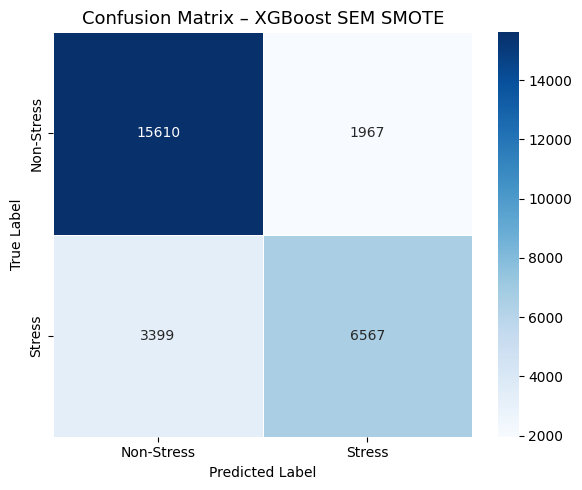

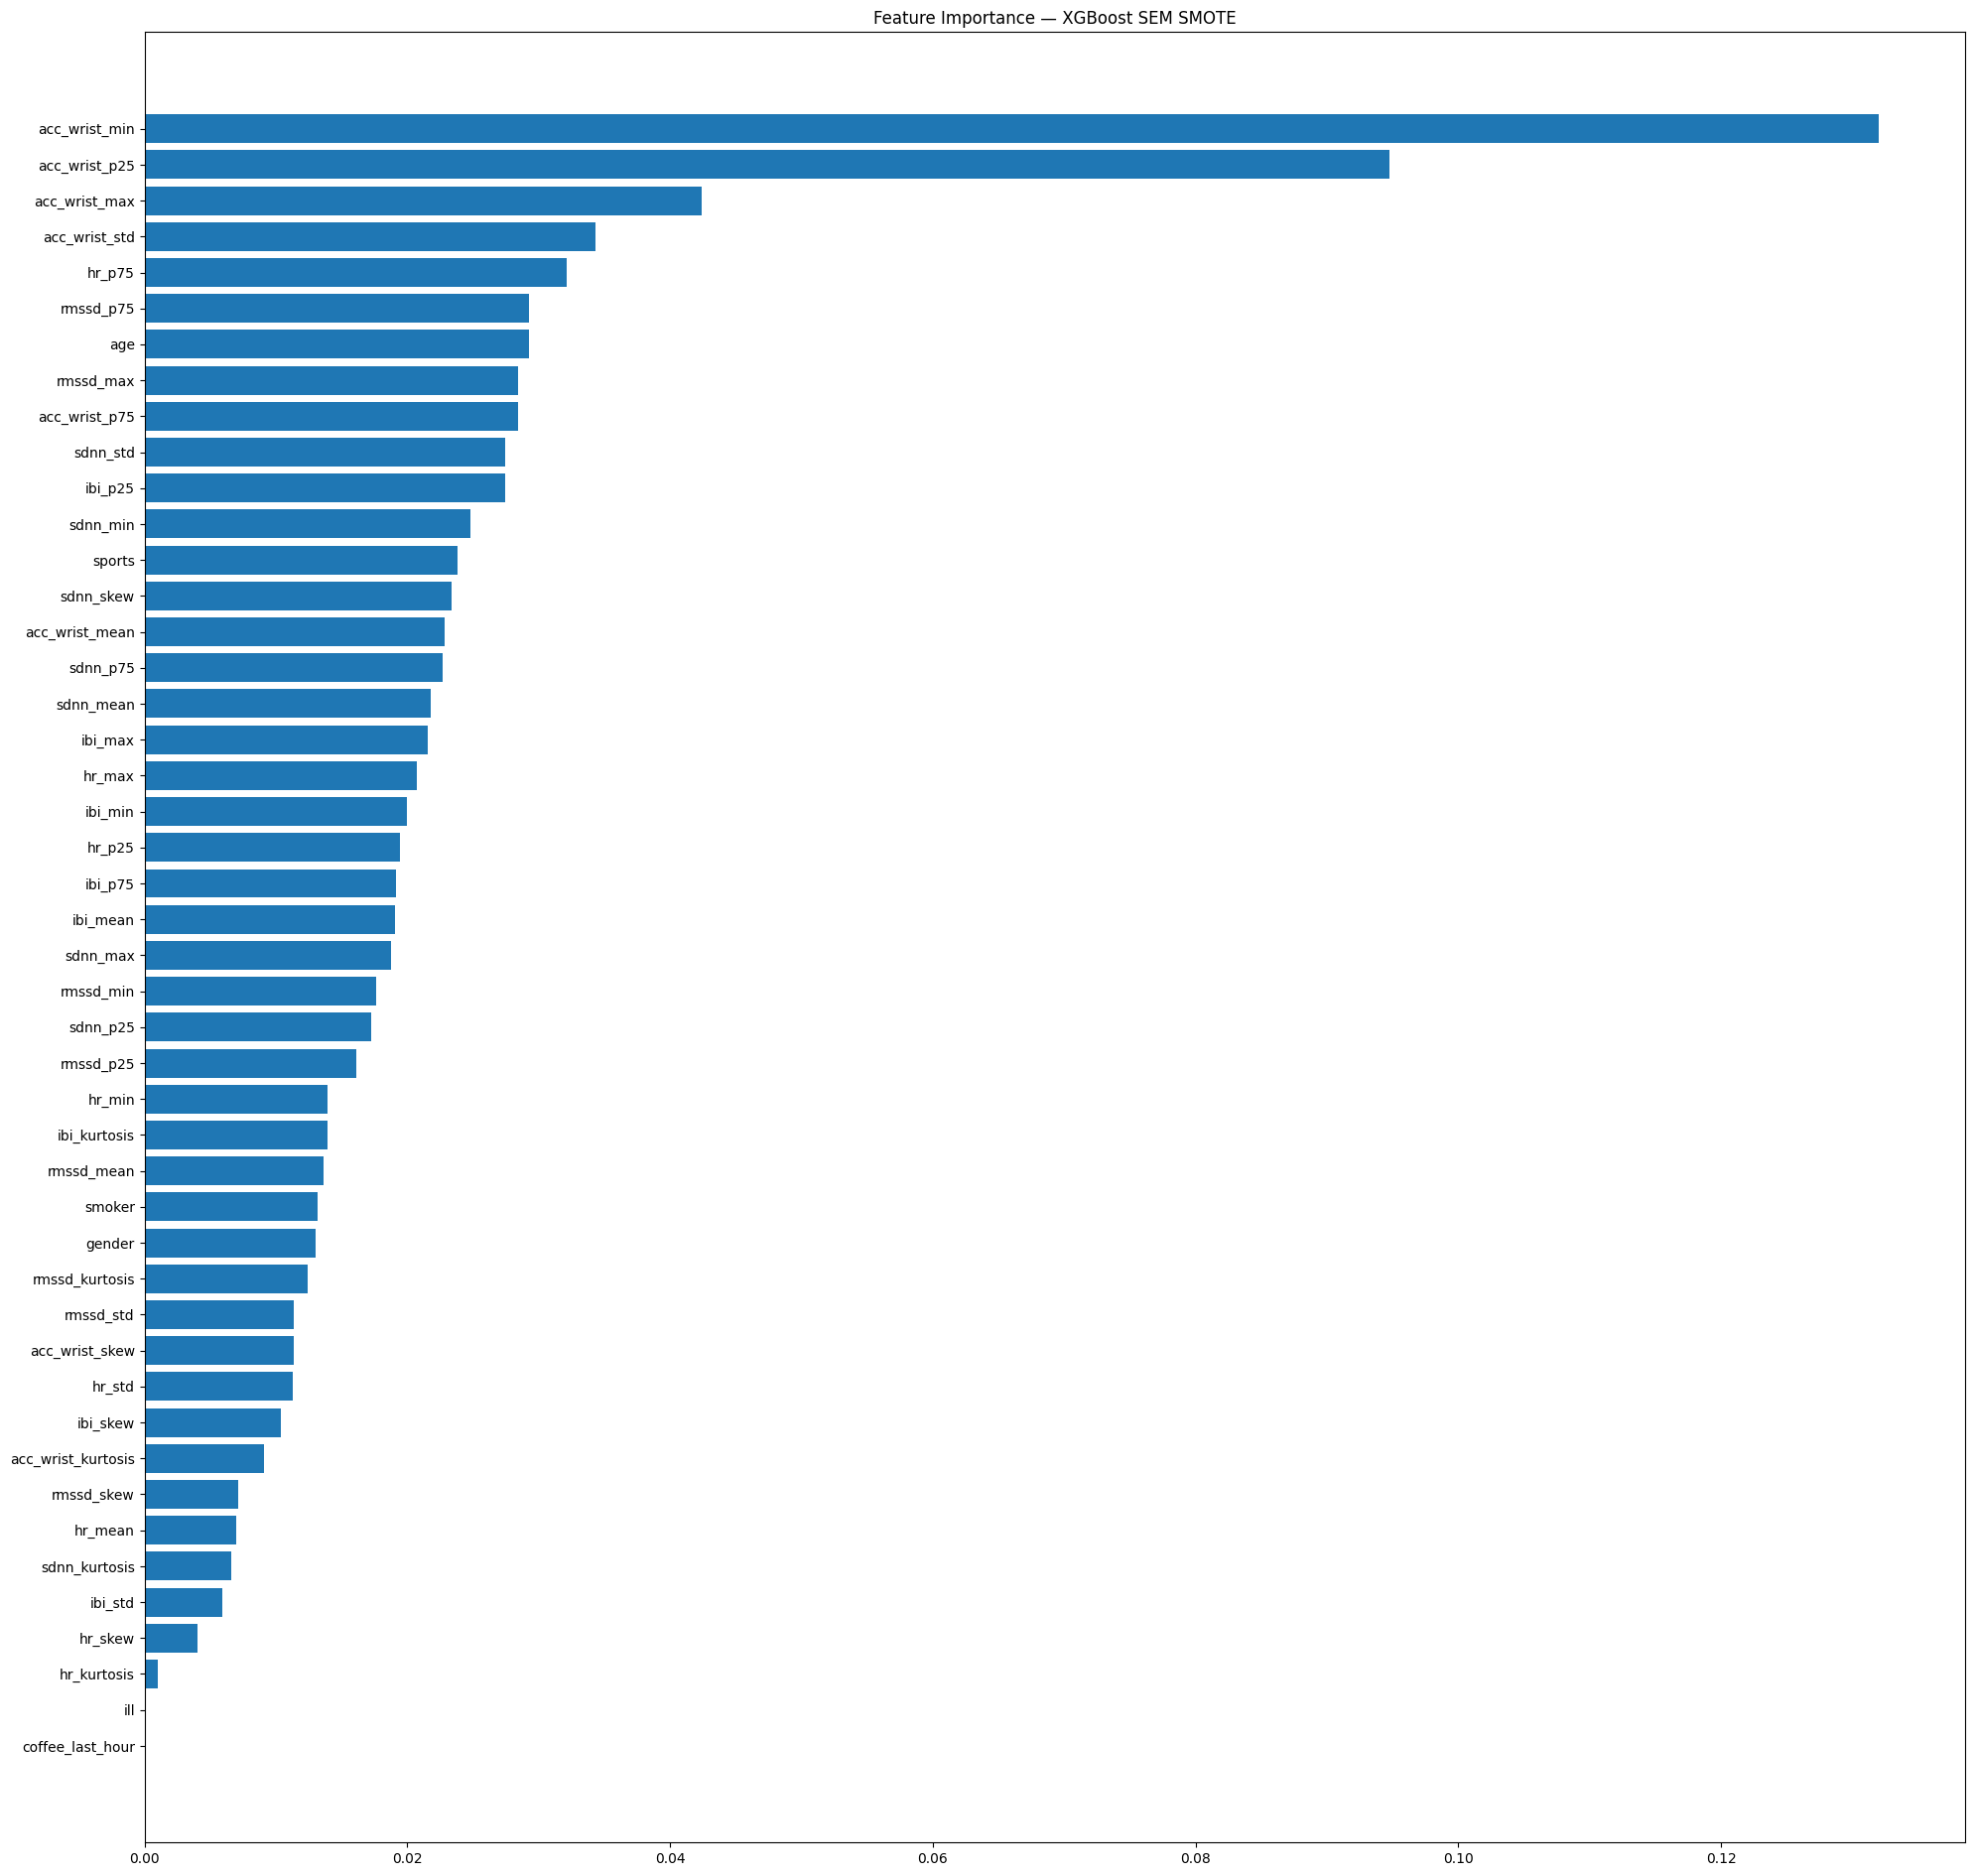

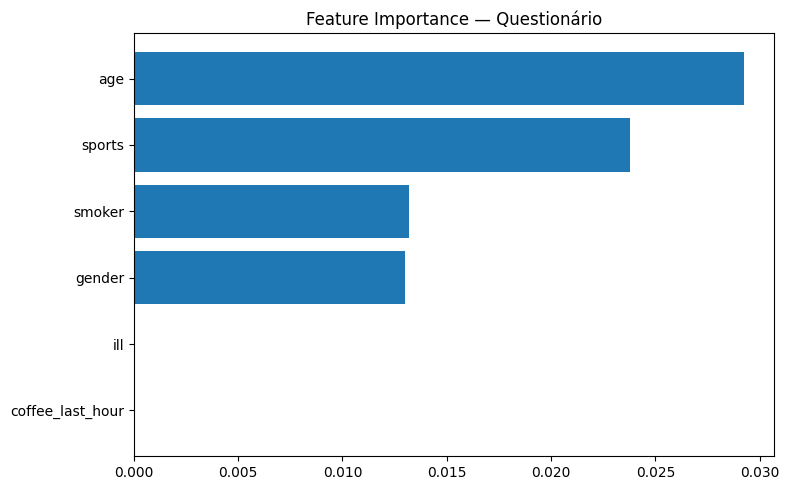

Guardado em: /kaggle/working/roc_data/xgb_no_smote.pkl


In [9]:
run_xgb(use_smote=True)
run_xgb(use_smote=False)

**Light GBM**

In [10]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings('ignore')
logo = LeaveOneGroupOut()

In [11]:
def objective(trial, use_smote):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.2),
        'num_leaves':        trial.suggest_int('num_leaves', 31, 127),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'subsample':         trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree':  trial.suggest_float('colsample_bytree', 0.6, 1.0),
    }
    f1_scores = []
    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_tr = imputer.fit_transform(scaler.fit_transform(X_train))
        X_te = imputer.transform(scaler.transform(X_test))

        if use_smote:
            X_tr, y_train = SMOTE(random_state=42).fit_resample(X_tr, y_train)

        model = LGBMClassifier(**params, device='cpu', random_state=42, verbose=-1)
        model.fit(X_tr, y_train)
        f1_scores.append(f1_score(y_test, model.predict(X_te), zero_division=0))
    return np.mean(f1_scores)

In [12]:
def evaluate_lgbm(X, y, groups, best_params, use_smote=True):
    logo = LeaveOneGroupOut()
    all_y_true, all_y_pred, all_y_probs = [], [], []
    fold_f1s, fold_mccs, all_cms = [], [], []
    last_model = None

    for train_idx, test_idx in logo.split(X, y, groups):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        scaler  = StandardScaler()
        imputer = SimpleImputer(strategy='mean')
        X_train = imputer.fit_transform(scaler.fit_transform(X_train))
        X_test  = imputer.transform(scaler.transform(X_test))

        if use_smote:
            X_train, y_train = SMOTE(random_state=42).fit_resample(X_train, y_train)

        model = LGBMClassifier(**best_params, device='cpu', random_state=42, verbose=-1)
        model.fit(X_train, y_train)
        last_model = model

        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        all_y_true.extend(y_test)
        all_y_pred.extend(y_pred)
        all_y_probs.extend(y_prob)
        fold_f1s.append(f1_score(y_test, y_pred, zero_division=0))
        fold_mccs.append(matthews_corrcoef(y_test, y_pred))
        all_cms.append(confusion_matrix(y_test, y_pred))

    return {
        'y_test':   np.array(all_y_true),
        'y_pred':   np.array(all_y_pred),
        'y_prob':   np.array(all_y_probs),
        'f1':       np.mean(fold_f1s),
        'f1_std':   np.std(fold_f1s),
        'accuracy': accuracy_score(all_y_true, all_y_pred),
        'bal_acc':  balanced_accuracy_score(all_y_true, all_y_pred),
        'mcc':      np.mean(fold_mccs),
        'roc_auc':  roc_auc_score(all_y_true, all_y_probs),
        'cm':       np.sum(all_cms, axis=0),
        'model':    last_model,
    }

In [13]:
def run_lgbm(use_smote):
    label = "COM SMOTE" if use_smote else "SEM SMOTE"
    print(f"\n{'='*50}\nA correr Optuna LightGBM {label}...\n{'='*50}")

    # Optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction='maximize')
    study.optimize(lambda trial: objective(trial, use_smote), n_trials=50)
    best_params = study.best_params
    print(f"Melhores parâmetros {label}: {best_params}")

    # Avaliação
    res = evaluate_lgbm(X, y, groups, best_params, use_smote=use_smote)

    # Métricas
    print(classification_report(res['y_test'], res['y_pred'], target_names=['Negativo', 'Positivo']))
    print(f"ROC-AUC:            {res['roc_auc']:.3f}")
    print(f"Balanced Accuracy:  {res['bal_acc']:.3f}")
    print(f"MCC:                {res['mcc']:.3f}")
    print(f"F1 Std (por fold):  {res['f1_std']:.3f}")

    # Confusion Matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        res['cm'], annot=True, fmt='d', cmap='Greens',
        xticklabels=['Negativo', 'Positivo'],
        yticklabels=['Negativo', 'Positivo'],
        linewidths=0.5, ax=ax
    )
    ax.set_title(f'Confusion Matrix – LightGBM {label}', fontsize=13)
    ax.set_xlabel('Predição'); ax.set_ylabel('Realidade')
    plt.tight_layout(); plt.show()

    # Feature Importance — todas
    importances = res['model'].feature_importances_
    indices     = np.argsort(importances)
    plt.figure(figsize=(20, 19))
    plt.barh(np.array(selected_features)[indices], importances[indices])
    plt.title(f"Feature Importance — LightGBM {label}")
    plt.tight_layout(); plt.show()

    # Feature Importance — Questionário
    quest_cols = [c for c in ['age', 'gender', 'coffee_last_hour', 'sports', 'smoker', 'ill']
                if c in list(selected_features)]
    if quest_cols:
        quest_indices = [list(selected_features).index(c) for c in quest_cols]
        quest_importances = res['model'].feature_importances_[quest_indices]
        indices = np.argsort(quest_importances)
        plt.figure(figsize=(8, 5))
        plt.barh(np.array(quest_cols)[indices], quest_importances[indices])
        plt.title('Feature Importance — Questionário')
        plt.tight_layout()
        plt.show()

    # Guardar pkl
    smote_tag = 'smote' if use_smote else 'no_smote'
    roc_data  = {k: v for k, v in res.items() if k != 'model'}
    roc_data.update({'smote': use_smote, 'best_params': best_params, 'model': 'LightGBM'})
    os.makedirs('/kaggle/working/roc_data', exist_ok=True)
    fname = f'/kaggle/working/roc_data/lgbm_{smote_tag}.pkl'
    with open(fname, 'wb') as f:
        pickle.dump(roc_data, f)
    print(f"Guardado em: {fname}")


A correr Optuna LightGBM COM SMOTE...
Melhores parâmetros COM SMOTE: {'n_estimators': 135, 'max_depth': 3, 'learning_rate': 0.018444249494781195, 'num_leaves': 38, 'min_child_samples': 50, 'subsample': 0.8630297454116554, 'colsample_bytree': 0.6894750386489357}
              precision    recall  f1-score   support

    Negativo       0.86      0.87      0.86     17577
    Positivo       0.77      0.74      0.75      9966

    accuracy                           0.83     27543
   macro avg       0.81      0.81      0.81     27543
weighted avg       0.82      0.83      0.82     27543

ROC-AUC:            0.822
Balanced Accuracy:  0.807
MCC:                0.632
F1 Std (por fold):  0.253


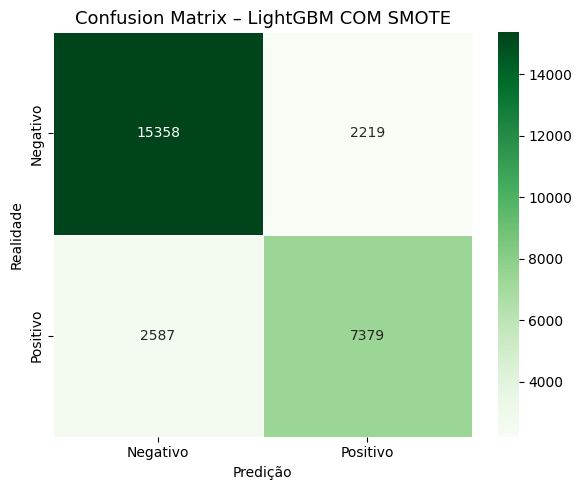

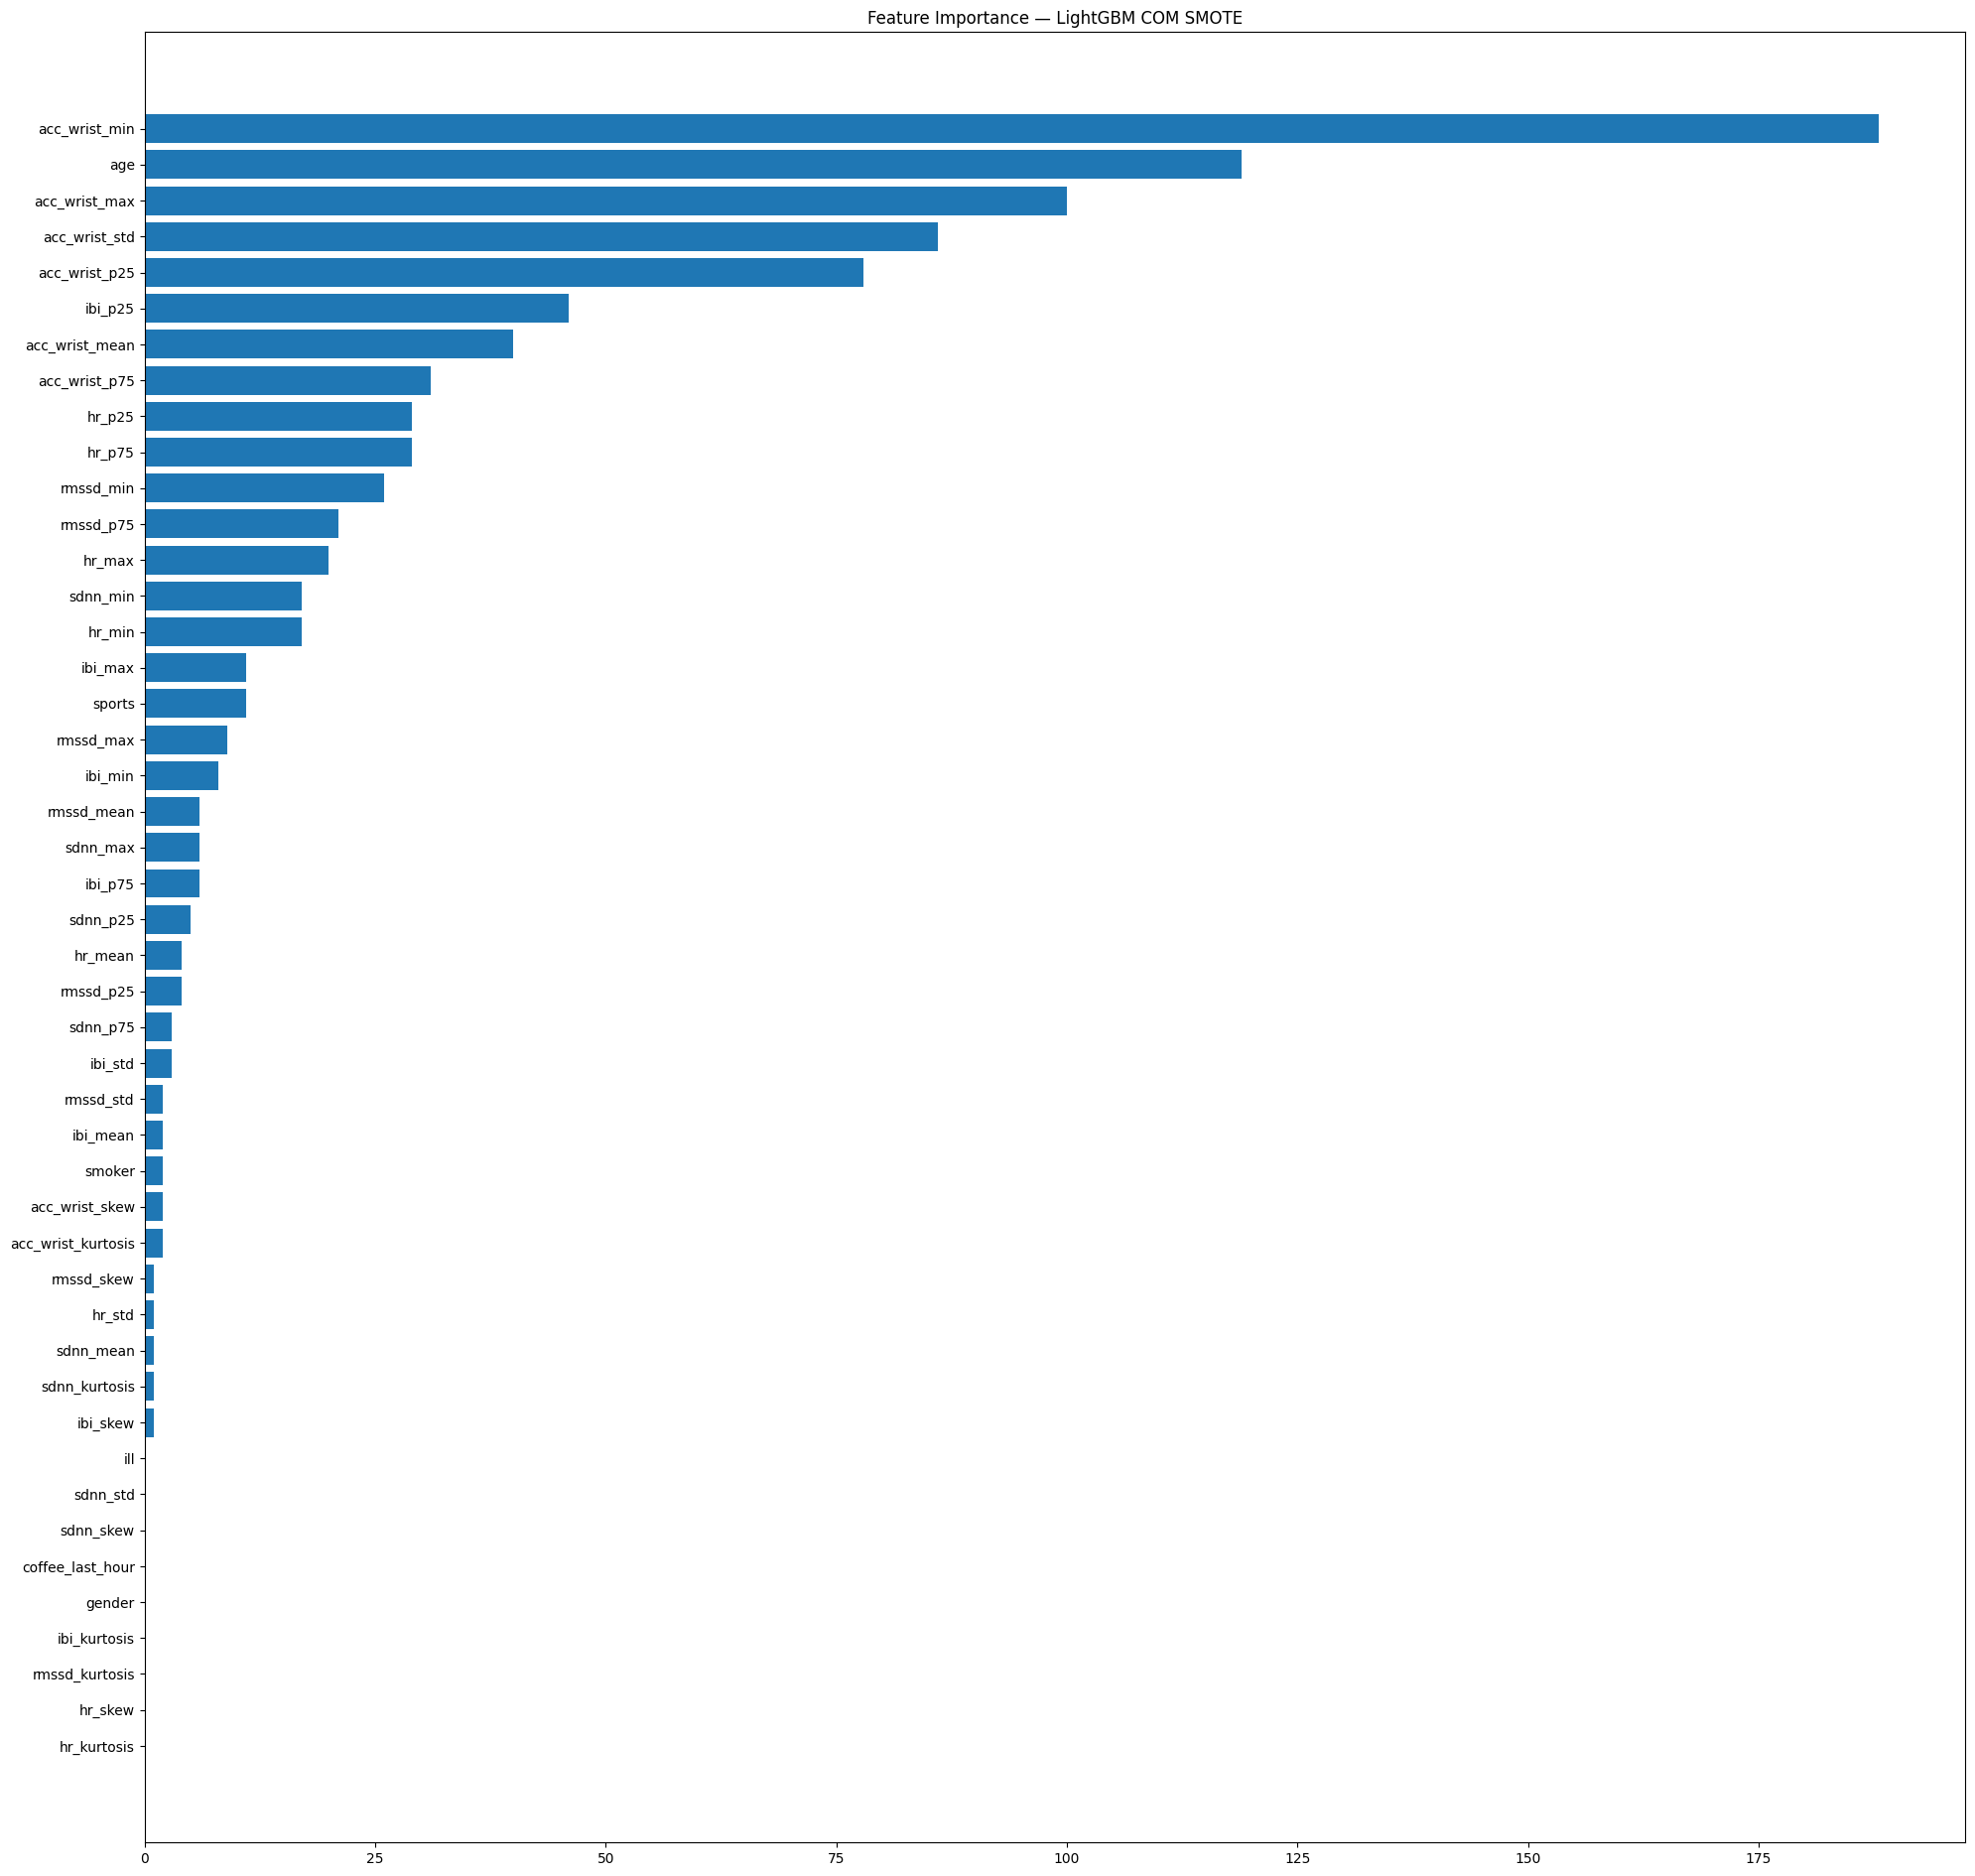

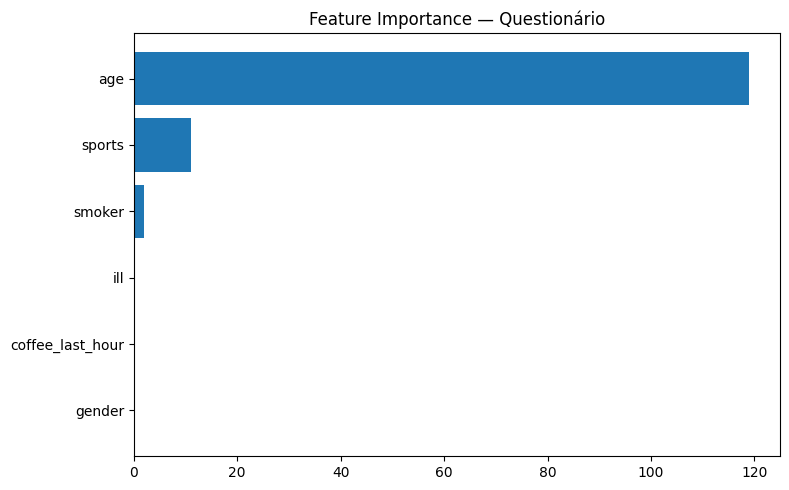

Guardado em: /kaggle/working/roc_data/lgbm_smote.pkl

A correr Optuna LightGBM SEM SMOTE...
Melhores parâmetros SEM SMOTE: {'n_estimators': 190, 'max_depth': 3, 'learning_rate': 0.012397988875777664, 'num_leaves': 47, 'min_child_samples': 45, 'subsample': 0.6724694375218166, 'colsample_bytree': 0.6229952949497575}
              precision    recall  f1-score   support

    Negativo       0.83      0.91      0.87     17577
    Positivo       0.81      0.67      0.74      9966

    accuracy                           0.83     27543
   macro avg       0.82      0.79      0.80     27543
weighted avg       0.82      0.83      0.82     27543

ROC-AUC:            0.827
Balanced Accuracy:  0.792
MCC:                0.619
F1 Std (por fold):  0.265


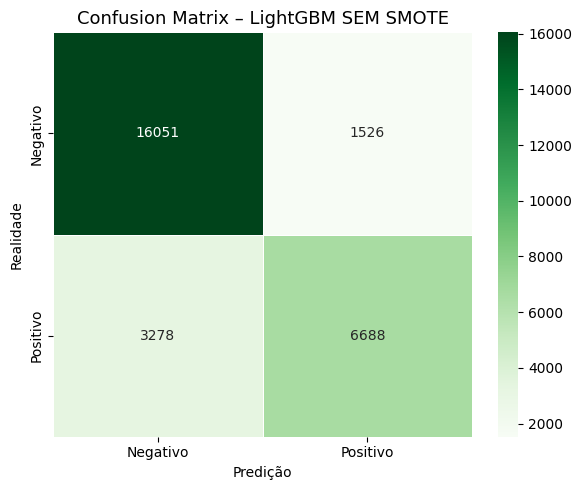

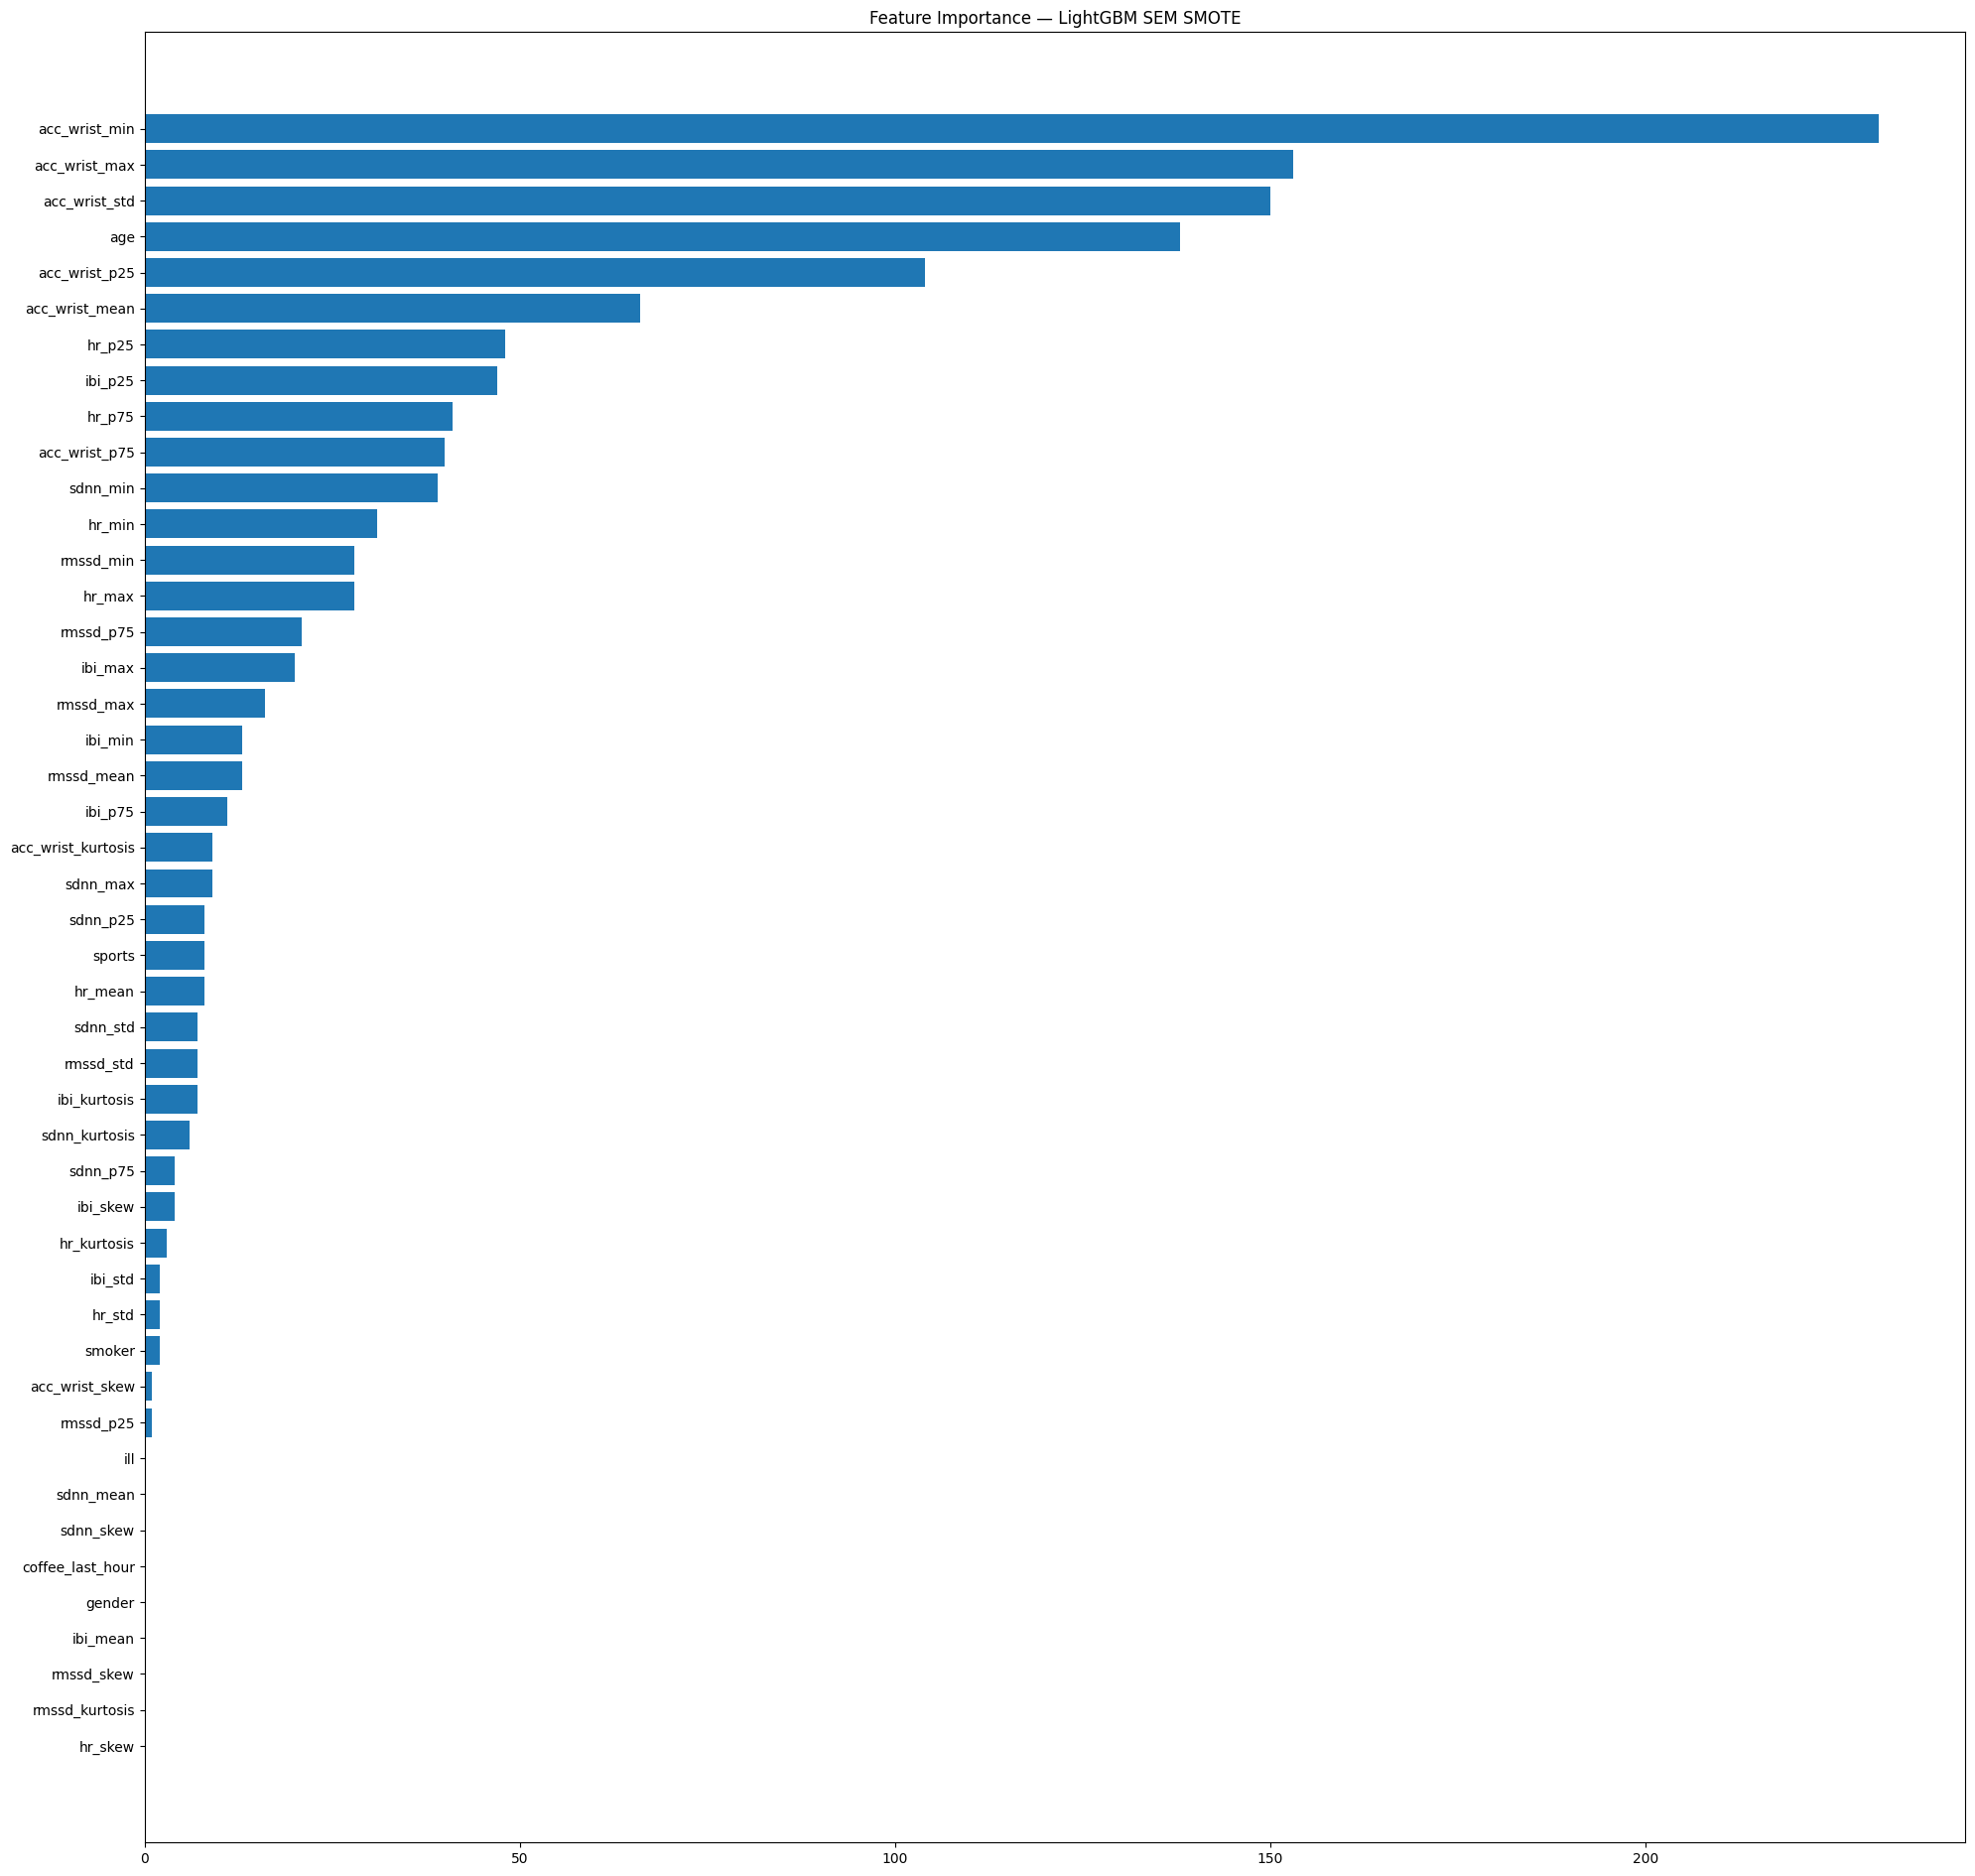

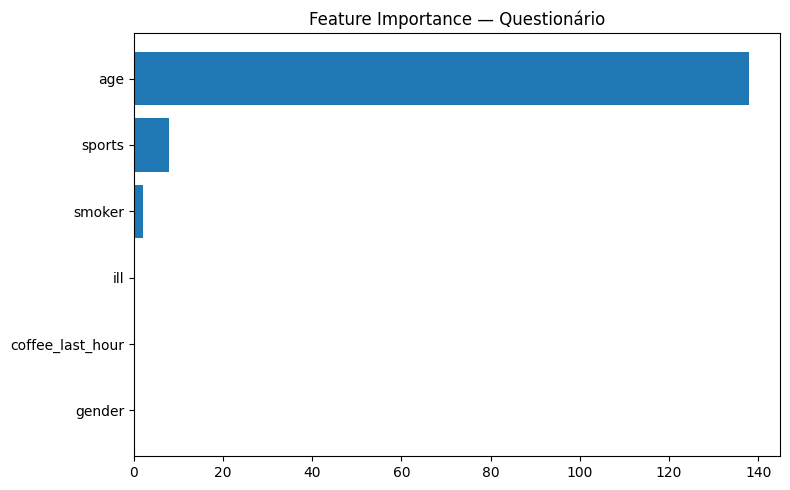

Guardado em: /kaggle/working/roc_data/lgbm_no_smote.pkl


In [14]:
run_lgbm(use_smote=True)
run_lgbm(use_smote=False)

In [15]:
best_params_lgbm = {
    'n_estimators': 161,
    'max_depth': 3,
    'learning_rate': 0.01932926886748418,
    'num_leaves': 50,
    'min_child_samples': 41,
    'subsample': 0.9727777463465864,
    'colsample_bytree': 0.7722747312265289
}

scaler_final = StandardScaler()
imputer_final = SimpleImputer(strategy='mean')
X_scaled = imputer_final.fit_transform(scaler_final.fit_transform(X))
X_res, y_res = SMOTE(random_state=42).fit_resample(X_scaled, y)

model_final = LGBMClassifier(**best_params_lgbm, device='cpu', random_state=42, verbose=-1)
model_final.fit(X_res, y_res)

with open('/kaggle/working/lgbm_wrist_final.pkl', 'wb') as f:
    pickle.dump({
        'model': model_final,
        'scaler': scaler_final,
        'imputer': imputer_final,
        'feature_cols': list(selected_features)  # <-- aqui estava o erro
    }, f)

print("Guardado!")

Guardado!
